# Indian Financial Fraud Detection — One Course-Aligned Model

This notebook builds one supervised fraud classifier with the synthetic Indian transaction dataset. It uses **XGBoost**, which is listed in the course syllabus under ensemble methods. The notebook follows the course workflow: inspect and prepare data, train a classifier, and evaluate it with a confusion matrix, accuracy, precision, recall, and F1.

The dataset is synthetic. Results are for coursework and are not evidence of performance on real bank transactions.


## What we are building

- **Task:** predict whether a transaction is fraudulent (`actual_is_fraud`).
- **Model:** one XGBoost boosted-tree classifier.
- **Features:** transaction details available at prediction time; identifiers, outcome fields, and pre-generated model outputs are excluded.
- **Evaluation:** train on earlier baseline transactions, select a decision threshold on baseline validation data, and report final results on the later drift-period holdout.

We use a time-ordered split because these transactions have timestamps. This gives a more realistic check on how a model trained on earlier data behaves on later transactions. We are not doing model comparisons or hyperparameter search in this first version.


## 1. Install packages and download the Kaggle dataset

Run this notebook in Google Colab. If Kaggle asks for authentication, add your Kaggle API token as a Colab secret named `KAGGLE_API_TOKEN`; do not paste the token into notebook cells.


In [5]:
!pip -q install kagglehub xgboost

import kagglehub

DATASET_HANDLE = 'neel1237/indian-fraud-transactions-for-monitoring'
dataset_dir = kagglehub.dataset_download(DATASET_HANDLE)
print('Dataset folder:', dataset_dir)


Dataset folder: /kaggle/input/datasets/neel1237/indian-fraud-transactions-for-monitoring


## 2. Load and check the data

Check that the expected file and target are present, inspect the row count and missing values, then look at the fraud rate over the dataset's monitoring periods.


In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 100)
RANDOM_STATE = 42

csv_files = list(Path(dataset_dir).rglob('*.csv'))
csv_path = next(path for path in csv_files if path.name == 'financial_fraud_monitoring_synthetic_770k.csv')
df = pd.read_csv(csv_path, low_memory=False)

required = {
    'transaction_id', 'event_timestamp_ist', 'label_available_at_ist',
    'transaction_amount_inr', 'monitoring_window', 'actual_is_fraud'
}
missing = required.difference(df.columns)
assert not missing, f'Missing required columns: {missing}'
assert len(df) == 770_000, f'Expected 770,000 rows; found {len(df):,}'

df['event_timestamp_ist'] = pd.to_datetime(df['event_timestamp_ist'])
df['label_available_at_ist'] = pd.to_datetime(df['label_available_at_ist'])
df = df.sort_values('event_timestamp_ist').reset_index(drop=True)

print('Shape:', df.shape)
print('Date range:', df['event_timestamp_ist'].min(), 'to', df['event_timestamp_ist'].max())
print('Missing values:', int(df.isna().sum().sum()))
print('Overall fraud rate: {:.2%}'.format(df['actual_is_fraud'].mean()))
display(df.head())
display(df.groupby('monitoring_window')['actual_is_fraud'].agg(
    transactions='size', fraud_rate='mean'
).style.format({'fraud_rate': '{:.2%}'}))


Shape: (770000, 33)
Date range: 2025-01-01 00:03:12+05:30 to 2025-12-31 23:58:54+05:30
Missing values: 0
Overall fraud rate: 7.69%


,transaction_id,event_timestamp_ist,transaction_date,monitoring_window,channel,region,customer_segment,merchant_category,merchant_risk_tier,currency,transaction_amount_inr,transaction_hour,day_of_week,card_present,international,device_trust_score,account_age_days,avg_transaction_amount_30d,amount_to_avg_ratio,days_since_last_txn,transaction_count_24h,failed_auth_24h,distance_from_home_km,is_new_merchant,is_high_risk_country,label_available_at_ist,actual_is_fraud,model_version,model_score,model_prediction,decision,data_drift_regime,concept_drift_regime
0,SYN-0000859,2025-01-01 00:03:12+05:30,2025-01-01,baseline,upi,Andhra Pradesh,small_business,retail,medium,INR,5701.99,0,Wednesday,no,no,69.6,570,3513.07,1.623,6,1,0,22.0,0,0,2025-01-08 21:03:12+05:30,1,fraud_model_v1.0,0.01839,0,approve,stable,none
1,SYN-0000378,2025-01-01 00:09:38+05:30,2025-01-01,baseline,ecommerce,Delhi,student,retail,medium,INR,1278.37,0,Wednesday,no,no,62.8,886,1194.24,1.070,0,1,0,1.3,0,0,2025-01-15 23:09:38+05:30,0,fraud_model_v1.0,0.02627,0,approve,stable,none
2,SYN-0001021,2025-01-01 00:09:54+05:30,2025-01-01,baseline,ecommerce,Rajasthan,salaried,retail,medium,INR,768.29,0,Wednesday,no,no,52.1,631,479.67,1.602,0,2,0,13.6,0,0,2025-01-22 00:09:54+05:30,0,fraud_model_v1.0,0.04061,0,approve,stable,none
3,SYN-0001722,2025-01-01 00:11:33+05:30,2025-01-01,baseline,pos,Delhi,salaried,cash_withdrawal,high,INR,435.44,0,Wednesday,yes,no,45.8,868,551.09,0.790,0,1,0,37.6,1,0,2025-01-29 01:11:33+05:30,0,fraud_model_v1.0,0.05786,0,approve,stable,none
4,SYN-0001290,2025-01-01 00:13:47+05:30,2025-01-01,baseline,ecommerce,Uttar Pradesh,mass_market,grocery,low,INR,2412.19,0,Wednesday,no,no,82.8,1227,3279.95,0.735,1,1,0,4.0,0,0,2025-01-15 18:13:47+05:30,0,fraud_model_v1.0,0.06109,0,approve,stable,none


,transactions,fraud_rate
monitoring_window,,
baseline,346500,5.22%
drift_period_1,169400,9.69%
drift_period_2,138600,11.64%
transition,115500,7.42%


## 3. Quick exploratory analysis

The fraud class is smaller than the legitimate class, so accuracy by itself can be misleading. We inspect fraud rates by channel and over time before training.


,transactions,fraud_rate
channel,,
ecommerce,138400,10.96%
imps_neft_rtgs,23287,7.68%
upi,331154,7.67%
mobile_banking,76972,7.59%
pos,169715,5.51%
atm,30472,5.39%


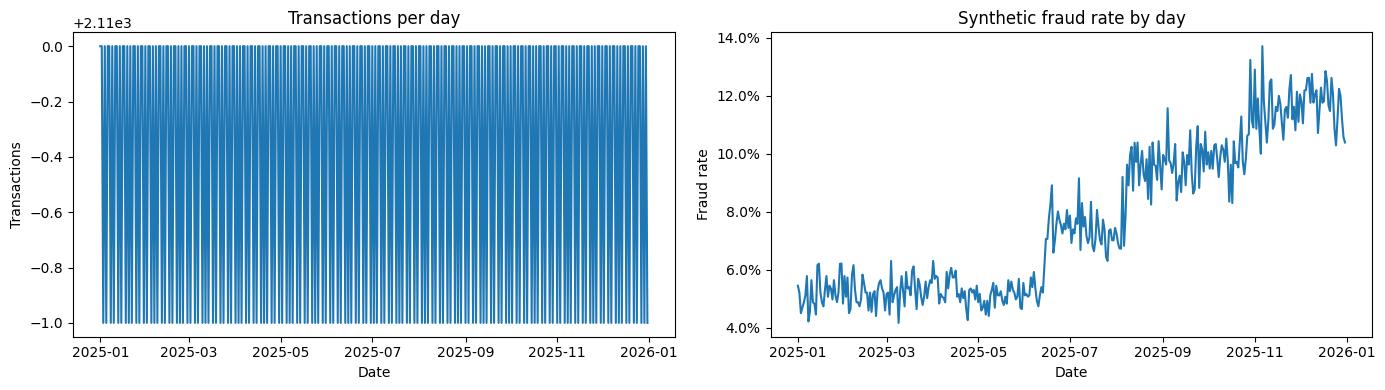

In [7]:
display(df.groupby('channel')['actual_is_fraud'].agg(
    transactions='size', fraud_rate='mean'
).sort_values('fraud_rate', ascending=False).style.format({'fraud_rate': '{:.2%}'}))

daily = (df.groupby(df['event_timestamp_ist'].dt.date)
           .agg(transactions=('transaction_id', 'size'), fraud_rate=('actual_is_fraud', 'mean'))
           .reset_index())
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(pd.to_datetime(daily['event_timestamp_ist']), daily['transactions'])
axes[0].set(title='Transactions per day', xlabel='Date', ylabel='Transactions')
axes[1].plot(pd.to_datetime(daily['event_timestamp_ist']), daily['fraud_rate'])
axes[1].set(title='Synthetic fraud rate by day', xlabel='Date', ylabel='Fraud rate')
axes[1].yaxis.set_major_formatter('{x:.1%}')
plt.tight_layout()
plt.show()


## 4. Prepare features and make a time-ordered split

We derive hour, weekday, and weekend from the transaction timestamp. We exclude identifiers, label availability time, the target, monitoring/drift labels, currency (constant), and old model outputs so the model cannot learn the answer from future or administrative fields.

The model trains on the first 80% of baseline transactions. To simulate what would have been known when training started, rows whose fraud labels were not available by the validation start are removed from training. The final holdout is the later `drift_period_2` window.


In [8]:
TARGET = 'actual_is_fraud'
TIME_COL = 'event_timestamp_ist'
LABEL_TIME_COL = 'label_available_at_ist'

df['tx_hour_ist'] = df[TIME_COL].dt.hour
df['tx_day_of_week'] = df[TIME_COL].dt.dayofweek
df['is_weekend'] = (df['tx_day_of_week'] >= 5).astype('int8')

excluded_columns = {
    TARGET, 'transaction_id', TIME_COL, LABEL_TIME_COL, 'transaction_date',
    'monitoring_window', 'data_drift_regime', 'concept_drift_regime',
    'model_version', 'model_score', 'model_prediction', 'decision',
    'transaction_hour', 'day_of_week', 'currency'
}
feature_columns = [column for column in df.columns if column not in excluded_columns]

baseline = df.loc[df['monitoring_window'].eq('baseline')].sort_values(TIME_COL).copy()
split_at = int(len(baseline) * 0.80)
train_df = baseline.iloc[:split_at].copy()
validation_df = baseline.iloc[split_at:].copy()
training_cutoff = validation_df[TIME_COL].min()
train_df = train_df.loc[train_df[LABEL_TIME_COL] <= training_cutoff].copy()
holdout_df = df.loc[df['monitoring_window'].eq('drift_period_2')].copy()

numeric_columns = train_df[feature_columns].select_dtypes(include=np.number).columns.tolist()
categorical_columns = [column for column in feature_columns if column not in numeric_columns]

print('Training rows:', f'{len(train_df):,}')
print('Validation rows:', f'{len(validation_df):,}')
print('Final holdout rows:', f'{len(holdout_df):,}')
print('Training labels available by:', training_cutoff)
print('Training fraud rate: {:.2%}'.format(train_df[TARGET].mean()))
print('Validation fraud rate: {:.2%}'.format(validation_df[TARGET].mean()))
print('Holdout fraud rate: {:.2%}'.format(holdout_df[TARGET].mean()))
print('Numeric features:', numeric_columns)
print('Categorical features:', categorical_columns)


Training rows: 240,482
Validation rows: 69,300
Final holdout rows: 138,600
Training labels available by: 2025-05-12 11:54:44+05:30
Training fraud rate: 5.71%
Validation fraud rate: 5.17%
Holdout fraud rate: 11.64%
Numeric features: ['transaction_amount_inr', 'device_trust_score', 'account_age_days', 'avg_transaction_amount_30d', 'amount_to_avg_ratio', 'days_since_last_txn', 'transaction_count_24h', 'failed_auth_24h', 'distance_from_home_km', 'is_new_merchant', 'is_high_risk_country', 'tx_hour_ist', 'tx_day_of_week', 'is_weekend']
Categorical features: ['channel', 'region', 'customer_segment', 'merchant_category', 'merchant_risk_tier', 'card_present', 'international']


## 5. Preprocess features and define the XGBoost model

The course covers converting categorical data to numeric data. We use one-hot encoding for categories and median imputation for numeric values. The XGBoost `scale_pos_weight` parameter gives the smaller fraud class more influence during training; it is calculated from the training rows only.


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier

numeric_preprocessing = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])
categorical_preprocessing = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('one_hot', OneHotEncoder(handle_unknown='ignore', sparse_output=True))
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_preprocessing, numeric_columns),
    ('categorical', categorical_preprocessing, categorical_columns)
])

fraud_count = int(train_df[TARGET].sum())
legitimate_count = len(train_df) - fraud_count
positive_class_weight = legitimate_count / fraud_count
print('scale_pos_weight:', round(positive_class_weight, 2))

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    tree_method='hist',
    scale_pos_weight=positive_class_weight,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', xgb_model)
])


scale_pos_weight: 16.51


## 6. Train the model

The model learns from the training portion only. The validation data is kept for selecting a decision threshold; the final holdout is kept until the last evaluation step.


In [10]:
model.fit(train_df[feature_columns], train_df[TARGET])
print('XGBoost model training complete.')


XGBoost model training complete.


## 7. Select a threshold using validation data

A model produces a fraud score. The default decision threshold is 0.50, but a lower threshold may catch more fraud and create more false alerts. We select the threshold that gives the best validation F1 score, then freeze it before evaluating the final holdout.


In [11]:
from sklearn.metrics import precision_recall_curve

validation_scores = model.predict_proba(validation_df[feature_columns])[:, 1]
precision_values, recall_values, thresholds = precision_recall_curve(
    validation_df[TARGET], validation_scores
)
f1_values = (2 * precision_values[:-1] * recall_values[:-1]) / (
    precision_values[:-1] + recall_values[:-1] + 1e-12
)
selected_threshold = float(thresholds[np.argmax(f1_values)])
print(f'F1-selected validation threshold: {selected_threshold:.4f}')


F1-selected validation threshold: 0.6892


## 8. Evaluate once on the later holdout

The final test window contains later transactions with a higher fraud rate than baseline. This is a useful time-shift check, but it also means the result may differ from validation. We report the required course metrics and PR-AUC, which is helpful when the target classes are imbalanced.


In [12]:
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score
)

holdout_scores = model.predict_proba(holdout_df[feature_columns])[:, 1]
y_true = holdout_df[TARGET].to_numpy()

def metric_row(name, threshold):
    y_pred = (holdout_scores >= threshold).astype(int)
    return {
        'Decision': name,
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'PR_AUC': average_precision_score(y_true, holdout_scores)
    }

results = pd.DataFrame([
    metric_row('Default threshold', 0.50),
    metric_row('Validation-selected threshold', selected_threshold)
]).set_index('Decision')
display(results.style.format({
    'Threshold': '{:.3f}', 'Accuracy': '{:.2%}', 'Precision': '{:.2%}',
    'Recall': '{:.2%}', 'F1': '{:.2%}', 'PR_AUC': '{:.3f}'
}))

print('Holdout fraud rate: {:.2%}'.format(y_true.mean()))
print('All-legitimate accuracy baseline: {:.2%}'.format((y_true == 0).mean()))


,Threshold,Accuracy,Precision,Recall,F1,PR_AUC
Decision,,,,,,
Default threshold,0.500,79.72%,29.11%,51.75%,37.26%,0.322
Validation-selected threshold,0.689,86.21%,40.34%,38.54%,39.42%,0.322


Holdout fraud rate: 11.64%
All-legitimate accuracy baseline: 88.36%


## 9. Confusion matrix and classification report

The confusion matrix shows correct and incorrect predictions at the validation-selected threshold. In fraud detection, false negatives are missed fraud cases; false positives are legitimate transactions flagged for review.


Rows are actual classes [legitimate, fraud]; columns are predicted classes [legitimate, fraud].


,Predicted legitimate,Predicted fraud
Actual legitimate,113273,9196
Actual fraud,9914,6217


              precision    recall  f1-score   support

  Legitimate       0.92      0.92      0.92    122469
       Fraud       0.40      0.39      0.39     16131

    accuracy                           0.86    138600
   macro avg       0.66      0.66      0.66    138600
weighted avg       0.86      0.86      0.86    138600



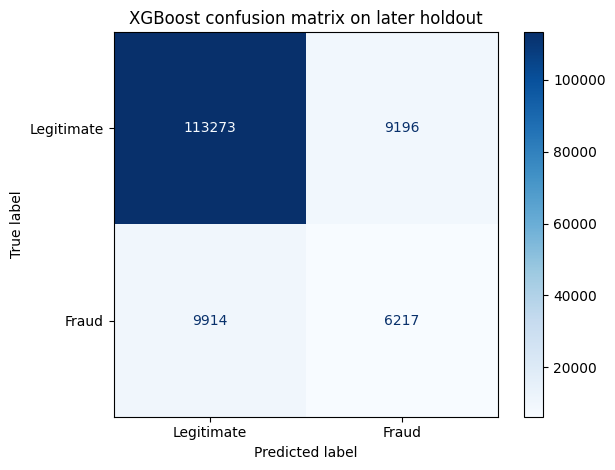

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay

holdout_predictions = (holdout_scores >= selected_threshold).astype(int)
cm = confusion_matrix(y_true, holdout_predictions, labels=[0, 1])
print('Rows are actual classes [legitimate, fraud]; columns are predicted classes [legitimate, fraud].')
display(pd.DataFrame(cm,
    index=['Actual legitimate', 'Actual fraud'],
    columns=['Predicted legitimate', 'Predicted fraud']))

print(classification_report(
    y_true, holdout_predictions,
    target_names=['Legitimate', 'Fraud'], zero_division=0
))
ConfusionMatrixDisplay.from_predictions(
    y_true, holdout_predictions,
    display_labels=['Legitimate', 'Fraud'], cmap='Blues', values_format='d'
)
plt.title('XGBoost confusion matrix on later holdout')
plt.tight_layout()
plt.show()


## 10. What to report

Report the validation-selected threshold and the holdout precision, recall, F1, PR-AUC, and confusion matrix. Explain the precision/recall tradeoff: lowering the threshold can catch more fraud, but it usually sends more legitimate transactions for review. Accuracy is included because it is in the syllabus, but compare it with the all-legitimate baseline so class imbalance is visible.

This is the first supervised model for the project. Later improvements can compare models or add cross-validation and grid search, which are also covered in the course.
